# connect to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# import all packages

In [ ]:
%%capture
!pip install torchmetrics
# !pip install torch==2.3.0 torchtext==0.18

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.4/891.4 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 59.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 62.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
import pandas as pd
import numpy as np
import re
from torchmetrics import F1Score, Accuracy, Precision, Recall, ConfusionMatrix
from tensorflow.keras.preprocessing.text import Tokenizer
import torch.nn as nn
import torch
import os
from itertools import groupby
from random import shuffle
from torch.nn.utils.rnn import pad_sequence
from collections import Counter
import matplotlib.pyplot as plt
from IPython.display import clear_output
import torch.nn.functional as F
from torchtext.vocab import GloVe
import torchtext
from torch.utils.data import Dataset, DataLoader
from functools import partial
import re
from enum import Enum
from typing import List, Optional, Tuple, Dict, Any, List, Union
from torch.autograd import Variable

/usr/local/lib/python3.10/dist-packages/torchtext/vocab/__init__.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)
/usr/local/lib/python3.10/dist-packages/torchtext/utils.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)


# Env Varaibles

In [ ]:
data_dir = "/content/drive/MyDrive/dataset_dir"
train_path = data_dir + "/train.txt"
val_path = data_dir + "/val.txt"
test_path = data_dir + "/test.txt"

# load data

In [ ]:
def get_statistics(x_train_text, x_test_text, x_val_text):
    combined_texts = x_train_text + x_test_text + x_val_text
    lens = [len(text.split()) for text in combined_texts]
    vocab_size = len(set(" ".join(combined_texts).split()))
    max_len = max(lens)
    min_len = min(lens)

    word_freq = Counter(word for text in combined_texts for word in text.split())
    freq_values = list(word_freq.values())
    max_freq = max(freq_values)
    min_freq = min(freq_values)
    mean_freq = np.mean(freq_values)
    std_freq = np.std(freq_values)

    print("================================= Text Length Statistics =================================")
    print(f"Minimum text length         | {min_len} words")
    print(f"Maximum text length         | {max_len} words")
    print(f"Vocabulary size             | {vocab_size} unique words")
    print("==========================================================================================\n")

    print("================================ Word Frequency Statistics ================================")
    print(f"Most common word frequency  | {max_freq}")
    print(f"Least common word frequency | {min_freq}")
    print(f"Average word frequency      | {mean_freq:.2f}")
    print(f"Standard deviation          | {std_freq:.2f}")
    print("==========================================================================================")

def remove_less_freq_words(x_train_text, y_train_text, threshold=4):
    word_freq = Counter(word for text in x_train_text for word in text.split())

    x_train_text_new, y_train_text_new = [], []

    for text, label in zip(x_train_text, y_train_text):
        filtered_text = ' '.join(word for word in text.split() if word_freq[word] > threshold)
        if filtered_text:
            x_train_text_new.append(filtered_text)
            y_train_text_new.append(label)

    return x_train_text_new, y_train_text_new

def clean_text(text):
    text = re.sub(r'[^\w\s.,!?\'\";:()-]', '', text)  # remove special characters
    text = text.lower().strip()                       # lower and strip
    return text

def load_file(file_path):
    x, y = [], []
    with open(file_path, "r") as f:
        lines = f.readlines()
        for line in lines:
            line = line.split(";")
            s = clean_text(" ".join(line[:-1]))
            t = clean_text(line[-1])
            x.append(s)
            y.append(t)

    return x, y

In [ ]:
x_train_text, y_train_text = load_file(train_path)
x_test_text, y_test_text = load_file(test_path)
x_val_text, y_val_text = load_file(val_path)

# checking the results
print(len(x_train_text), len(x_test_text), len(x_val_text))
print(len(y_train_text), len(y_test_text), len(y_val_text))

for i in range(10):
    print(y_train_text[i], "===> ", x_train_text[i])

16000 2000 2000
16000 2000 2000
sadness ===>  i didnt feel humiliated
sadness ===>  i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
anger ===>  im grabbing a minute to post i feel greedy wrong
love ===>  i am ever feeling nostalgic about the fireplace i will know that it is still on the property
anger ===>  i am feeling grouchy
sadness ===>  ive been feeling a little burdened lately wasnt sure why that was
surprise ===>  ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny
fear ===>  i feel as confused about life as a teenager or as jaded as a year old man
joy ===>  i have been with petronas for years i feel that petronas has performed well and made a huge profit
love ===>  i feel romantic too


In [ ]:
get_statistics(x_train_text, x_test_text, x_val_text)

================================= Text Length Statistics =================================
Minimum text length         | 2 words
Maximum text length         | 66 words
Vocabulary size             | 17096 unique words

================================ Word Frequency Statistics ================================
Most common word frequency  | 32242
Least common word frequency | 1
Average word frequency      | 22.39
Standard deviation          | 346.36


In [ ]:
x_train_text, y_train_text = remove_less_freq_words(x_train_text, y_train_text, threshold=3)
x_test_text, y_test_text = remove_less_freq_words(x_test_text, y_test_text, threshold=1)
x_val_text, y_val_text = remove_less_freq_words(x_val_text, y_val_text, threshold=1)

In [ ]:
get_statistics(x_train_text, x_test_text, x_val_text)

================================= Text Length Statistics =================================
Minimum text length         | 1 words
Maximum text length         | 63 words
Vocabulary size             | 4504 unique words

================================ Word Frequency Statistics ================================
Most common word frequency  | 32242
Least common word frequency | 2
Average word frequency      | 80.33
Standard deviation          | 671.40


# label encoding

In [ ]:
class_cat = ['sadness', 'surprise', 'anger', 'love', 'joy', 'fear']  # list(set(y_train_text))
y_train = [class_cat.index(i) if i in class_cat else "<OOV>" for i in y_train_text]
y_test = [class_cat.index(i) if i in class_cat else "<OOV>" for i in y_test_text]
y_val = [class_cat.index(i) if i in class_cat else "<OOV>" for i in y_val_text]

n_class = len(class_cat)
print(f"number of classes: {n_class}")
print(f"class_cat: {class_cat}")
print(y_train_text[:10])
print(y_train[:10])

number of classes: 6
class_cat: ['sadness', 'surprise', 'anger', 'love', 'joy', 'fear']
['sadness', 'sadness', 'anger', 'love', 'anger', 'sadness', 'surprise', 'fear', 'joy', 'love']
[0, 0, 2, 3, 2, 0, 1, 5, 4, 3]


# simple glove embedder

In [ ]:
class GloveTokenizer:
    def __init__(self, n_emb):
        self.glove = GloVe(name='6B', dim=n_emb, cache='.vector_cache')
        self.itos = self.glove.itos + ['<unk>', '<pad>']
        self.stoi = {word: i for i, word in enumerate(self.itos)}

        self.unk_token = '<unk>'
        self.pad_token = '<pad>'
        self.unk_id = self.stoi[self.unk_token]
        self.pad_id = self.stoi[self.pad_token]

    def encode(self, text):
        idx = [self.stoi.get(word, self.unk_id) for word in text.split()]
        return idx

    @property
    def vocab_size(self):
        return len(self.stoi)

class GloveEmbedder(nn.Module):
    def __init__(self, n_emb):
        super(GloveEmbedder, self).__init__()
        glove = GloVe(name='6B', dim=n_emb, cache='.vector_cache')

        unk_emb = glove.vectors.mean(dim=0, keepdim=True)
        pad_emb = torch.zeros(1, n_emb)

        self.emb = nn.Embedding.from_pretrained(torch.cat([glove.vectors, unk_emb, pad_emb]), freeze=True)

    def forward(self, idx):
        idx_tensor = torch.tensor(idx, dtype=torch.long) if isinstance(idx, list) else idx
        return self.emb(idx_tensor)


# Example usage
tokenizer = GloveTokenizer(n_emb=100)
embedder = GloveEmbedder(n_emb=100)

# Example text
text = "hello world this is a test ismail haha hihi <pad>"

# Tokenize and Embed
idx = tokenizer.encode(text)
emb = embedder(idx)

print("Token Indices:", idx)
print("Emb Shape:", emb.shape)

.vector_cache/glove.6B.zip: 862MB [08:32, 1.68MB/s]                           
100%|█████████▉| 399999/400000 [00:28<00:00, 13983.65it/s]


Token Indices: [13075, 85, 37, 14, 7, 728, 8734, 154265, 400000, 400001]
Emb Shape: torch.Size([10, 100])


# glove Data Loader: Ordering Words by size

In [ ]:
class GloveDataLoader(object):
    def __init__(
        self,
        texts,
        labels,
        tok_in_batch,
        tokenizer,
        min_seq_len,
        max_seq_len,
        is_train=True):

        self.tok_in_batch = tok_in_batch
        self.is_train = is_train
        self.tokenizer = tokenizer
        self.max_seq_len = max_seq_len
        self.min_seq_len = min_seq_len

        # texts' lengths
        txt_lens = [len(self.tokenizer.encode(text)) for text in texts]

        # put all text, label, len together
        self.data = list(zip(texts, labels, txt_lens))

        # Filter by min and max
        self.data = [(x, y, s) for x, y, s in self.data if min_seq_len <= s <= max_seq_len]

        if self.is_train:
            self.data.sort(key=lambda x: x[2])  # Sort by length of text

        self.create_batches()

    def create_batches(self):
        if self.is_train:
            chunks = [list(t) for _, t in groupby(self.data, key=lambda x: x[2])] # group by txt_len

            self.batches = list()
            for chunk in chunks:
                # tok_in_batch // txt_len ==> How many txt_len to put in tok_in_batch
                seq_per_batch = ( self.tok_in_batch // chunk[0][2] )

                # chunk ==> batches
                self.batches.extend([chunk[i : i + seq_per_batch] for i in range(0, len(chunk), seq_per_batch)])

            shuffle(self.batches)  # Randomly shuffle batchs
            self.n_batches = len(self.batches)
        else:
            self.batches = [[d] for d in self.data]
            shuffle(self.batches)
            self.n_batches = len(self.batches)

    def __iter__(self):

        return self

    def __len__(self):
        return self.n_batches

    def __next__(self):
        if self.n_batches == 0:
            raise StopIteration

        b_idx  = torch.randint(0, self.n_batches, (1,)).item()

        texts, labels, text_lens = zip(*self.batches[b_idx])

        # Tokenize text and add padding
        text_idx = [self.tokenizer.encode(t) for t in texts]

        # pad text < max_seq_len
        text_idx = [
            t + [self.tokenizer.pad_id] * (self.max_seq_len - len(t)) if len(t) < self.max_seq_len else t
            for t in text_idx
        ]

        text_idx = torch.LongTensor(text_idx)
        labels = torch.LongTensor(labels)
        text_lens = torch.LongTensor(text_lens)

        return text_idx, labels, text_lens


# let's test our dataloader
tokenizer = GloveTokenizer(n_emb=100)

data_loader = GloveDataLoader(
    texts=x_train_text,
    labels=y_train,
    tok_in_batch=1000,
    tokenizer=tokenizer,
    min_seq_len=3,
    max_seq_len=50,
    is_train=True)

In [ ]:
# Test the data loader by printing the first batch
for idx, (x, y, s) in enumerate(data_loader):
    print("x :", x.shape)
    print("y :", y.shape)
    print("s :", s.shape)
    print("x :", x)
    print("y :", y)
    print("s :", s)

    break
    # if idx > -1:
    #   break

x : torch.Size([43, 50])
y : torch.Size([43])
s : torch.Size([43])
x : tensor([[    41,    998,     12,  ..., 400001, 400001, 400001],
        [ 14663,      7,     12,  ..., 400001, 400001, 400001],
        [    41,    456,    998,  ..., 400001, 400001, 400001],
        ...,
        [    41,    998,    192,  ..., 400001, 400001, 400001],
        [    41,     33,   1349,  ..., 400001, 400001, 400001],
        [    41,    998,    117,  ..., 400001, 400001, 400001]])
y : tensor([4, 4, 0, 2, 1, 2, 2, 2, 2, 0, 4, 0, 4, 4, 0, 0, 1, 0, 4, 5, 0, 5, 5, 3,
        5, 4, 4, 4, 2, 2, 4, 5, 2, 3, 0, 0, 4, 4, 4, 4, 0, 0, 0])
s : tensor([23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23,
        23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23,
        23, 23, 23, 23, 23, 23, 23])


# Pytorch Dataloader

In [ ]:
class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, min_len, max_len):
        self.data = [
            (self.truncate(tokenizer.encode(text), max_len), label)
            for text, label in zip(texts, labels)
            if min_len <= len(tokenizer.encode(text))
        ]
    def truncate(self, idx, max_len):
        return idx[:max_len] if len(idx) > max_len else idx

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x, y = self.data[idx]
        return x, y


def pad_collate_fn(bch, tokenizer, max_len):
    (idx, lbl) = zip(*bch)

    pad = [
        i + [tokenizer.pad_id] * (max_len - len(i)) if len(i) < max_len else i
        for i in idx
    ]

    pad = torch.LongTensor(pad)
    lbl = torch.LongTensor(lbl)

    return pad, lbl

# let's test our dataloader
tokenizer = GloveTokenizer(n_emb=100)

# data loader
dataset = TextDataset(x_train_text, y_train, tokenizer, min_len=3, max_len=50)

data_loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=50))

In [ ]:
# Test the data loader by printing the first batch
for x, y in data_loader:
    print("x :", x.shape)
    print("y :", y.shape)
    print(f"min, max : {x.min()}, {x.max()}")
    break

x : torch.Size([32, 50])
y : torch.Size([32])
min, max : 0, 400001


# Training Helpers

##### Data parameters and Init Tokenizer, Data loaders

In [ ]:
# Data Parameters
max_seq_len = 40
min_seq_len = 3
b_size = 64
n_emb = 100

In [ ]:
# Tokenizer / fit
tokenizer = GloveTokenizer(n_emb=n_emb)

# train
train_dataset = TextDataset(x_train_text, y_train, tokenizer, min_len=min_seq_len, max_len=max_seq_len)
train_loader = DataLoader(
    train_dataset,
    batch_size=b_size,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=max_seq_len))

# val
val_dataset = TextDataset(x_val_text, y_val, tokenizer, min_len=min_seq_len, max_len=max_seq_len)
val_loader = DataLoader(
    val_dataset,
    batch_size=b_size,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=max_seq_len))

# test
test_dataset = TextDataset(x_test_text, y_test, tokenizer, min_len=min_seq_len, max_len=max_seq_len)
test_loader = DataLoader(
    test_dataset,
    batch_size=b_size,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=max_seq_len))

##### Training and Validation Helpers

In [ ]:
def validator(model, data_loader, criterion, n_step, device):
    model.eval()
    tot_loss = 0
    true_preds = 0
    tot_sample = 0

    with torch.no_grad():
        for step, (x, true_y) in enumerate(data_loader):
            x = x.to(device)
            true_y = true_y.to(device)

            # Forward pass
            logits = model(x)

            # loss / acc
            loss = criterion(logits, true_y)
            tot_loss += loss.item() * true_y.size(0)

            _, preds = torch.max(logits, 1) # val, idx
            true_preds += (preds == true_y).sum().item()
            tot_sample += true_y.size(0)

            if step >= n_step:
                break

    avg_loss = tot_loss   / tot_sample
    avg_acc  = true_preds / tot_sample
    return avg_loss, avg_acc

def trainer(model, data_loader, criterion, optimizer, n_step, max_norm=None, device="cpu"):
    model.train()
    tot_loss = 0
    true_preds = 0
    tot_sample = 0
    update_ratios = []

    for step, (x, true_y) in enumerate(data_loader):
        x, true_y = x.to(device), true_y.to(device)

        # Forward pass
        logits = model(x)

        # Calculate loss
        loss = criterion(logits, true_y)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()

        # update ratios before the optimizer step
        total_ratio = 0
        count_params_with_grad = 0
        for param in model.parameters():
            if param.grad is not None:
                param_scale = param.norm().item() if param.norm() != 0 else 1
                update_scale = (param.grad * -lr).norm().item()
                update_ratio = update_scale / param_scale
                total_ratio += update_ratio
                count_params_with_grad += 1

        # average ratio
        avg_ratio = total_ratio / count_params_with_grad if count_params_with_grad else 0
        update_ratios.append(avg_ratio)

        # Gradient clipping to prevent exploding gradients
        if max_norm:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)

        # optimization
        optimizer.step()

        # loss, acc
        tot_loss += loss.item() * true_y.size(0)
        _, preds = torch.max(logits, 1) # val, idx
        true_preds += (preds == true_y).sum().item()
        tot_sample += true_y.size(0)

        if step >= n_step:
            break

    avg_loss = tot_loss   / tot_sample
    avg_acc  = true_preds / tot_sample
    avg_up_ratio = sum(update_ratios) / len(update_ratios) if update_ratios else 0
    return avg_loss, avg_acc, avg_up_ratio

def tester(model, data_loader, criterion, n_step, device):
    model.eval()
    tot_loss = 0
    true_preds = 0
    tot_sample = 0
    precision_metric = Precision(task='multiclass', average='macro', num_classes=6).to(device)
    recall_metric = Recall(task='multiclass', average='macro', num_classes=6).to(device)
    f1_metric = F1Score(task='multiclass', average='macro', num_classes=6).to(device)
    confusion_matrix = ConfusionMatrix(task='multiclass', num_classes=6).to(device)

    with torch.no_grad():
        for step, (x, true_y) in enumerate(data_loader):
            x = x.to(device)
            true_y = true_y.to(device)

            # Forward pass
            logits = model(x)

            # Calculate loss and accumulate
            loss = criterion(logits, true_y)
            tot_loss += loss.item() * true_y.size(0)

            # Predictions
            _, preds = torch.max(logits, 1)
            true_preds += (preds == true_y).sum().item()
            tot_sample += true_y.size(0)

            # Update metrics
            precision_metric.update(preds, true_y)
            recall_metric.update(preds, true_y)
            f1_metric.update(preds, true_y)
            confusion_matrix.update(preds, true_y)

            if step >= n_step:
                break

    # Calculate average loss and accuracy
    avg_loss = tot_loss / tot_sample
    avg_acc = true_preds / tot_sample
    precision = precision_metric.compute().item()
    recall = recall_metric.compute().item()
    f1 = f1_metric.compute().item()
    conf_matrix = confusion_matrix.compute().cpu().numpy()

    print("\n" + "="*40)
    print(f"{' '*10}Test Results Summary")
    print("="*40)
    print(f"{'Metric':<20} | {'Value':>15}")
    print("-"*40)
    print(f"{'Average Loss':<20} | {avg_loss:>15.4f}")
    print(f"{'Accuracy':<20} | {avg_acc * 100:>14.2f}%")
    print(f"{'Precision':<20} | {precision:>15.4f}")
    print(f"{'Recall':<20} | {recall:>15.4f}")
    print(f"{'F1 Score':<20} | {f1:>15.4f}")
    print("="*40)

    # Display Confusion Matrix
    print("\nConfusion Matrix:")
    print("-"*60)
    print(" " * 5, end="")
    for i in range(conf_matrix.shape[1]):
        print(f"{i:^8}", end=" ")
    print("\n" + "-"*60)

    for i, row in enumerate(conf_matrix):
        print(f"{i:<5}", end="")
        for val in row:
            print(f"{val:^8}", end=" ")
        print()

    print("-"*60)



def live_plot_triple(data_dict, figsize=(18, 5), title="Model Training Progress"):
    clear_output(wait=True)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=figsize)

    # Loss plot
    if "tr_loss_avg" in data_dict and data_dict["tr_loss_avg"]:
        ax1.plot(data_dict["tr_loss_avg"], "r-", label="Train Loss Avg", marker='o')
    if "vl_loss_avg" in data_dict and data_dict["vl_loss_avg"]:
        ax1.plot(data_dict["vl_loss_avg"], "b-", label="Val Loss Avg", marker='o')
    ax1.set_title("Training & Validation Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc='upper left')
    ax1.grid(True)

    # Accuracy plot
    if "tr_acc_avg" in data_dict and data_dict["tr_acc_avg"]:
        ax2.plot(data_dict["tr_acc_avg"], "r--", label="Train Acc Avg", alpha=0.7, marker='x')
    if "vl_acc_avg" in data_dict and data_dict["vl_acc_avg"]:
        ax2.plot(data_dict["vl_acc_avg"], "b--", label="Val Acc Avg", alpha=0.7, marker='x')
    ax2.set_title("Training & Validation Accuracy")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy (%)")
    ax2.legend(loc='upper right')
    ax2.grid(True)

    # Update Ratio plot
    ax3.axhline(y=0.001, color='r', linestyle='--', label='Reference (10^-3)')
    if "avg_up_ratio" in data_dict and data_dict["avg_up_ratio"]:
        ax3.plot(data_dict["avg_up_ratio"], "g-", label="Average Update Ratios", marker='^')
    ax3.set_title("Parameter Update Ratios")
    ax3.set_xlabel("Epochs")
    ax3.set_ylabel("Update Ratio")
    ax3.legend(loc='upper right')
    ax3.grid(True)

    fig.suptitle(title)
    plt.show()

def get_lr(epoch, lr, gamma, min_lr):
    d_lr = lr * (gamma ** epoch)
    return max(d_lr, min_lr)

def update_lr(optimizer: torch.optim.Optimizer, new_lr: float):
    for param_group in optimizer.param_groups:
        param_group["lr"] = new_lr

# RNN (PyTorch API nn.RNN)

In [ ]:
class GlovePyRNN(nn.Module):
    def __init__(
        self, n_emb, h_dim, n_unit, n_class,
        act="relu", brnn=False, bias=True, d_rate=0.0, device="cpu"
    ):
        super(GlovePyRNN, self).__init__()

        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.brnn = brnn
        self.n_emb = n_emb

        self.emb = GloveEmbedder(n_emb=self.n_emb)

        self.rnn = nn.RNN(
            input_size=self.n_emb,
            hidden_size=self.h_dim,
            num_layers=self.n_unit,
            bias=bias,
            dropout=self.d_rate,
            batch_first=True,
            bidirectional=self.brnn,
            nonlinearity=act,
        )

        self.fc = nn.Sequential(
            nn.Linear(self.h_dim * 2 if self.brnn else self.h_dim, 2 * self.h_dim),
            nn.ReLU(),
            nn.Linear(2 * self.h_dim, self.n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = self.emb(x)             # (b, t, e)
        _, hn = self.rnn(x)         # (b, t, h)

        if self.brnn:
            hn = hn.view(self.n_unit, 2, b, self.h_dim)  # (n_unit, 2, b, h)
            h_fwd = hn[-1, 0]                     # (b, h)
            h_bwd = hn[-1, 1]                     # (b, h)
            x = torch.cat((h_fwd, h_bwd), dim=1)  # (b, h*2)
        else:
            x = hn[-1, :, :]                      # (b, h)

        x = self.dropout(x)                       # (b, h or h*2)
        x = self.fc(x)                            # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = GlovePyRNN(
    n_emb=100,
    h_dim=128,
    n_unit=2,
    n_class=6,
    bias=True,
    d_rate=0.3,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100 # cannot change this (glove embedding)
h_dim = 128
n_unit = 2
n_class = len(class_cat)
d_rate = 0.2
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 4e-3
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 100
n_step = 20

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = GlovePyRNN(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    n_class=n_class,
    bias=True,
    brnn=True,
    d_rate=d_rate,
    device=device,
)
model.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

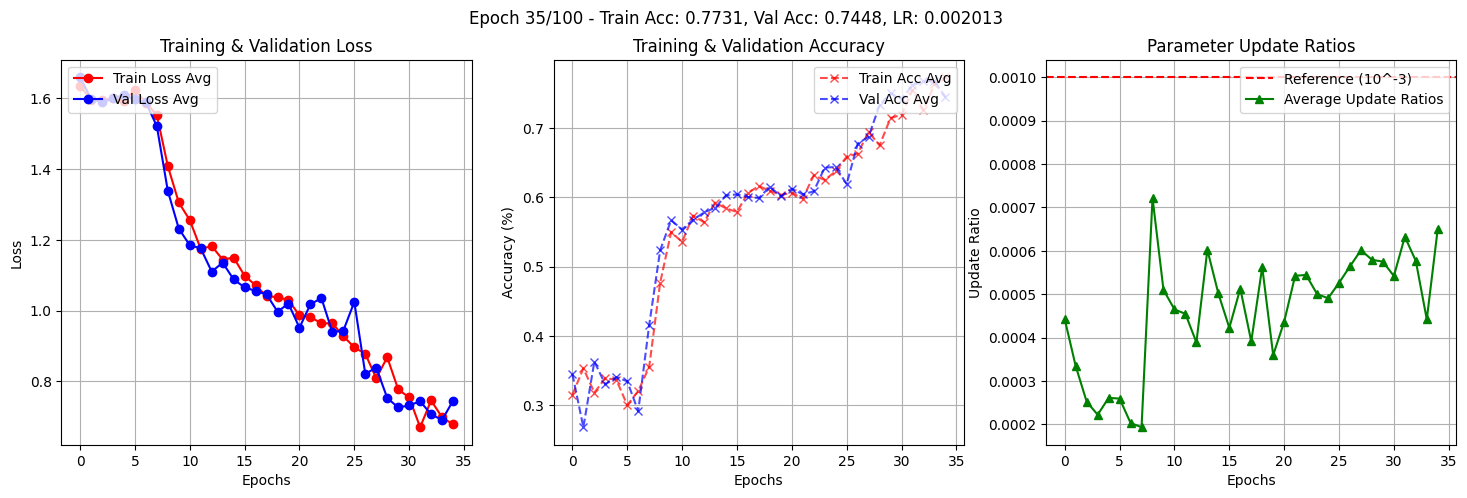

New best validation accuracy: 0.8013, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.77:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.6463
Accuracy             |          79.55%
Precision            |          0.7229
Recall               |          0.6729
F1 Score             |          0.6436

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      532       2        15       27       1        4     
1       1        4        4        21       6        30    
2       16       0       218       8        2        31    
3       7        0        5       132       12       3     
4       9        0        5       110      565       6     
5       9        0        67       8        0       140    
------------------------------------------------------------


# RNN ( Implementation From scratch )

In [ ]:
class RNN(nn.Module):
    def __init__(self, in_dim, h_dim, act='relu', is_res=True, bias = False, device = "cpu"):
        super(RNN, self).__init__()
        self.h_dim = h_dim
        self.device = device
        self.bias = bias
        self.is_res = is_res

        self.i2h = nn.Linear(in_features=in_dim, out_features=h_dim, bias=bias, device=device)
        self.h2h = nn.Linear(in_features=h_dim, out_features=h_dim, bias=bias, device=device)

        if in_dim != h_dim:
            self.res_proj = nn.Linear(in_features=in_dim, out_features=h_dim, bias=bias, device=device)
        else:
            self.res_proj = None

        if act == 'relu':
            self.act_fun = nn.ReLU()
        elif act == 'tanh':
            self.act_fun = nn.Tanh()
        else:
            raise ValueError("Unsupported activation function")

        self._init_params()

    def _init_params(self):
        for param in self.parameters():
            if param.dim() > 1:
                if isinstance(self.act_fun, nn.ReLU):     # Kaiming (He)
                    nn.init.kaiming_uniform_(param, nonlinearity='relu')
                elif isinstance(self.act_fun, nn.Tanh):   # Xavier (Glorot)
                    nn.init.xavier_uniform_(param)
            else:
                nn.init.constant_(param, 0)

    def forward(self, x, h=None):
        if h is None:
            h = torch.zeros(x.size(0), self.h_dim, device=x.device)

        h = self.act_fun(self.i2h(x) + self.h2h(h)) + self.res_proj(x) * 0.5 if self.res_proj else h + x * 0.5

        return h

In [ ]:
class RNNBlock(nn.Module):
    def __init__(self, in_dim, h_dim, n_unit, act='relu', bias = False, device = "cpu"):
        super(RNNBlock, self).__init__()
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device

        self.units = nn.ModuleList([
            RNN(in_dim=in_dim, h_dim=h_dim, act=act, bias=bias, device=device) for _ in range(n_unit)
            ])

    def forward(self, x, h=None):
        if x.shape[1] != self.n_unit:
            raise ValueError(f"Expected input sequence length of {self.n_unit}, but got {x.shape[1]}")

        for i, unit in enumerate(self.units):
            h = unit(x[:, i, :], h)

        return h

In [ ]:
class GloveRNN(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, n_class, bias=True, d_rate=0.0, device="cpu"):
        super(GloveRNN, self).__init__()

        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.n_emb = n_emb

        self.emb = GloveEmbedder(n_emb=self.n_emb)

        self.rnn = RNNBlock(
            in_dim=self.n_emb,
            h_dim=self.h_dim,
            n_unit=self.n_unit,
            act="relu",
            bias=bias,
            device=device,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = self.emb(x)    # (b, t, e)
        x = self.rnn(x)    # (b, t, h)
        x = self.dropout(x)  # (b, h or h*2)
        x = self.fc(x)       # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = GloveRNN(
    n_emb=100,
    h_dim=100,
    n_unit=20,
    n_class=6,
    bias=True,
    d_rate=0.3,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100 # fixed
h_dim = 100 # to use pure residual connection :)
n_unit = max_seq_len
n_class = len(class_cat)
d_rate = 0.1
max_norm = 5.0

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 2e-3
min_lr = 1e-5
betas = (0.99, 0.994)
alpha = 0.9
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.97

# Training configuration
n_epoch = 100
n_step = 20

# Early stopping parameters
patience = 60
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = GloveRNN(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    n_class=n_class,
    bias=True,
    d_rate=d_rate,
    device=device,
)
model.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

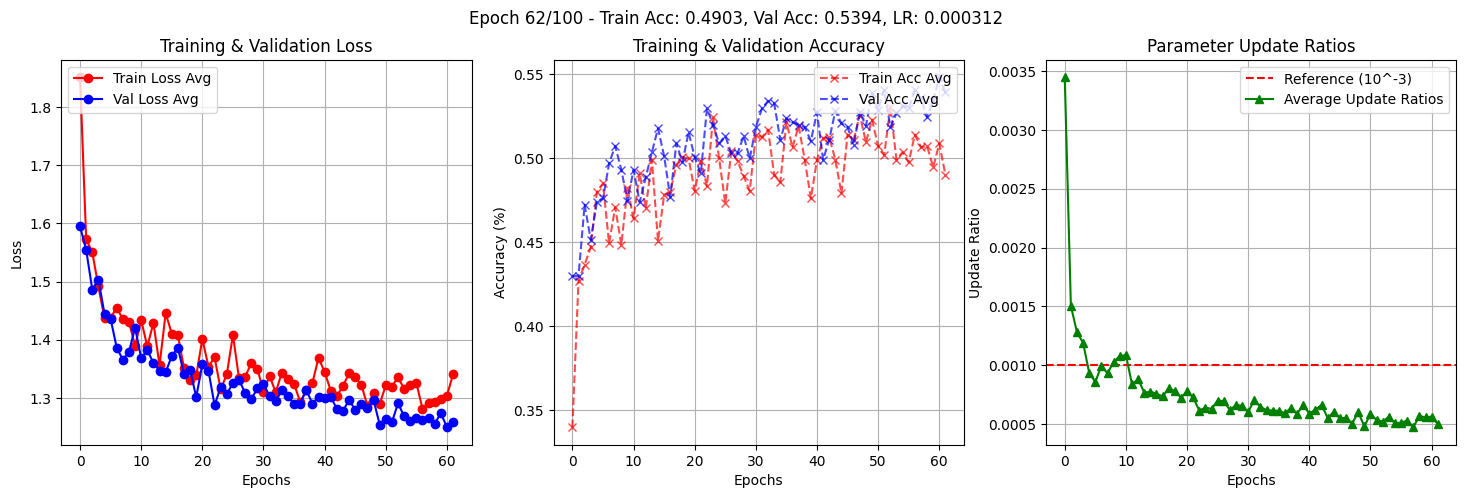

New best validation accuracy: 0.5506, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.55:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          1.2616
Accuracy             |          55.60%
Precision            |          0.5562
Recall               |          0.3537
F1 Score             |          0.3531

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      394       0        40       6       114       27    
1       18       2        4        0        29       13    
2      117       0        77       2        49       30    
3       40       0        10       8        98       3     
4       90       0        14       10      573       8     
5       98       0        17       1        50       58    
------------------------------------------------------------


# LSTM (PyTorch API nn.LSTM)

In [ ]:
class GlovePyLSTM(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, n_class, brnn=False, bias=True, d_rate=0.0, device="cpu"):
        super(GlovePyLSTM, self).__init__()

        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.brnn = brnn
        self.n_emb = n_emb

        self.emb = GloveEmbedder(n_emb=self.n_emb)

        self.rnn = nn.LSTM(
            input_size=self.n_emb,
            hidden_size=self.h_dim,
            num_layers=self.n_unit,
            bias=bias,
            dropout=self.d_rate,
            batch_first=True,
            bidirectional=self.brnn,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim * 2 if brnn else h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = self.emb(x)             # (b, t, e)
        _, (hn, _) = self.rnn(x)    # (b, t, h)

        if self.brnn:
            hn = hn.view(self.n_unit, 2, b, self.h_dim)  # (n_unit, 2, b, h)
            h_fwd = hn[-1, 0]                     # (b, h)
            h_bwd = hn[-1, 1]                     # (b, h)
            x = torch.cat((h_fwd, h_bwd), dim=1)  # (b, h*2)
        else:
            x = hn[-1, :, :]                      # (b, h)

        x = self.dropout(x)                       # (b, h or h*2)
        x = self.fc(x)                            # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = GlovePyLSTM(
    n_emb=100,
    h_dim=128,
    n_unit=2,
    n_class=6,
    brnn=True,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100 # should fixed
h_dim = 128
n_unit = 2
n_class = len(class_cat)
d_rate = 0.0
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 1e-2
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 100
n_step = 10

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = GlovePyLSTM(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    n_class=n_class,
    brnn=True,
    bias=True,
    d_rate=d_rate,
    device=device,
)
model.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

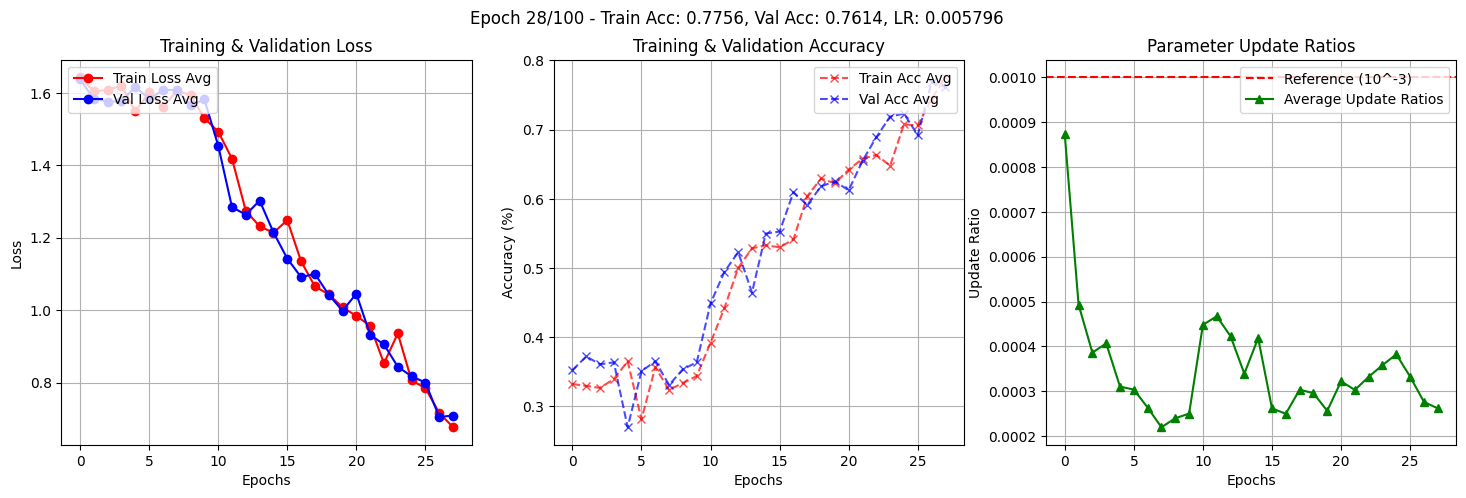

New best validation accuracy: 0.7898, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.78:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.6454
Accuracy             |          79.45%
Precision            |          0.6254
Recall               |          0.6325
F1 Score             |          0.6271

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      504       0        12       2        42       21    
1       5        0        21       8        22       10    
2       14       0       193       1        15       52    
3       2        0        3        87       67       0     
4       20       0        4        35      633       3     
5       18       0        27       3        4       172    
------------------------------------------------------------


# LSTM ( Implementation From scratch )

In [ ]:
class LSTM(nn.Module):
    def __init__(self, in_dim, h_dim, bias = False, device = 'cpu'):
        super(LSTM, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.bias = bias
        self.device = device

        self.i2h = nn.Linear(in_dim, h_dim * 4, bias=bias).to(device)    # [b, s, 4*o]
        self.h2h = nn.Linear(h_dim, h_dim * 4, bias=bias).to(device)   # [b, o, 4*o]

        if in_dim != h_dim:
            self.res_proj = nn.Linear(in_dim, h_dim, bias=bias)
        else:
            self.res_proj = None

        self.init_parameters()
        self.to(device)

    def init_parameters(self):
        std = 1.0 / torch.sqrt(torch.tensor(self.in_dim, dtype=torch.float))
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, xh = None):
        if xh is None:
            xh = Variable(x.new_zeros(x.size(0), self.h_dim))  # [b, o]
            xh = (xh, xh)

        xh, xc = xh

        gts = self.i2h(x) + self.h2h(xh)                # [b, s, 4*o]
        igt, fgt, cgt, ogt = gts.chunk(4, 1)            # gts ==> [i, f, c, o]

        i = torch.sigmoid(igt)                          # [b, s, o]
        f = torch.sigmoid(fgt)                          # [b, s, o]
        g = torch.tanh(cgt)                             # [b, s, o]
        o = torch.sigmoid(ogt)                          # [b, s, o]

        yc = xc * f + i * g                             # [b, s, o]
        yh = o * torch.tanh(yc)                         # [b, s, o]


        yh = yh + self.res_proj(x) * 0.5 if self.res_proj is not None else yh + x * 0.5

        return (yh, yc)

In [ ]:
class LSTMBlock(nn.Module):
    def __init__(self, in_dim, h_dim, n_unit, bias = False, device = "cpu"):
        super(LSTMBlock, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device

        self.units = nn.ModuleList([LSTM(in_dim=in_dim, h_dim=h_dim, bias=bias, device=device) for _ in range(n_unit)])

    def forward(self, x, xh = None):
        b, s, _ = x.shape   # [b, s, e]

        if xh is None:
            h0 = Variable(torch.zeros(self.n_unit, b, self.h_dim, device=self.device))            # [s, b, o]
        else:
            h0 = xh                                                                               # [s, b, o]

        xhs = [(h0[u, :, :], h0[u, :, :]) for u in range(self.n_unit)]

        for i in range(s):
            chr = x[:, i, :]                            # [b, e]
            unit = self.units[i]                        # one LSTM unit
            xhs[i] = None if i == 0 else xhs[i - 1]
            uh = unit(chr, xhs[i])                      # [b, h], [b, h]
            xhs[i] = uh

        return uh[0]

In [ ]:
class GloveLSTM(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, n_class, bias=True, d_rate=0.0, device="cpu"):
        super(GloveLSTM, self).__init__()

        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.n_emb = n_emb

        self.emb = GloveEmbedder(n_emb=self.n_emb)

        self.rnn = LSTMBlock(
            in_dim=self.n_emb,
            h_dim=self.h_dim,
            n_unit=self.n_unit,
            bias=bias,
            device=self.device,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim, 3 * h_dim),
            nn.ReLU(),
            nn.Linear(3 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = self.emb(x)    # (b, t, e)
        x = self.rnn(x)    # (b, t, h)

        x = self.dropout(x)  # (b, h or h*2)
        x = self.fc(x)       # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = GloveLSTM(
    n_emb=100,
    h_dim=128,
    n_unit=20,
    n_class=6,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100 # should be fixed (glove embedding size)
h_dim = 100
n_unit = max_seq_len
n_class = len(class_cat)
d_rate = 0.5
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 2e-3
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 400
n_step = 20

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = GloveLSTM(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    n_class=n_class,
    bias=True,
    d_rate=d_rate,
    device=device,
)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

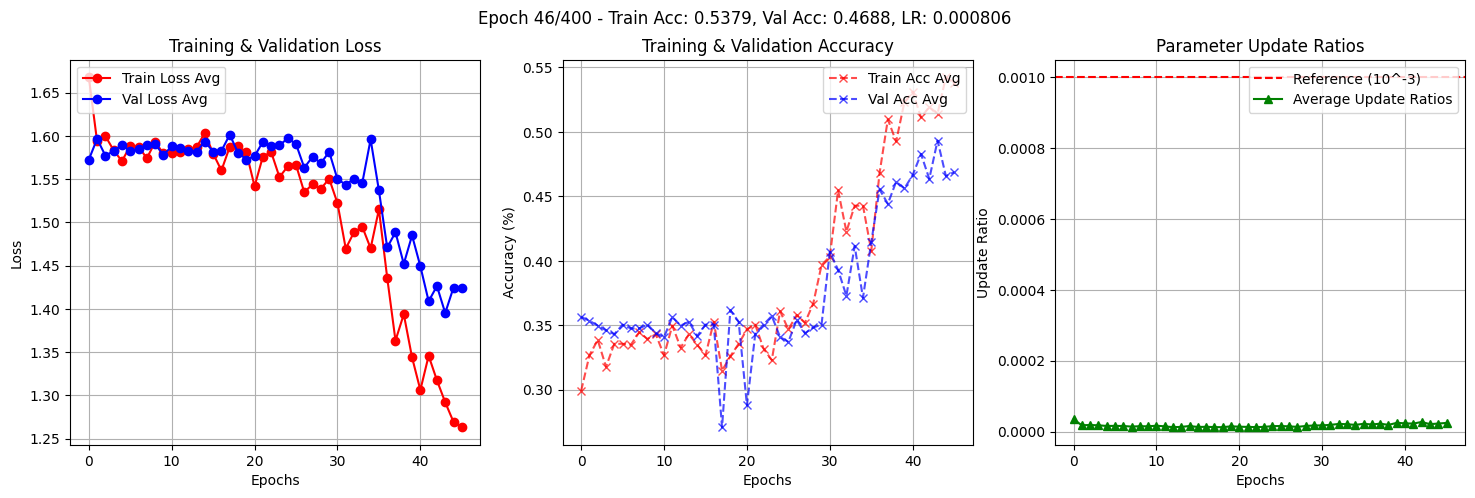

New best validation accuracy: 0.5149, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.5:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          1.3567
Accuracy             |          50.25%
Precision            |          0.2314
Recall               |          0.2634
F1 Score             |          0.2112

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      441       0        5        4       129       2     
1       36       0        1        0        28       1     
2      223       0        3        2        47       0     
3       43       0        1        0       114       1     
4      122       1        5        6       560       1     
5      186       1        1        2        33       1     
------------------------------------------------------------


# GRU (PyTorch API nn.GRU)

In [ ]:
class GlovePyGRU(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, n_class, brnn=False, bias=True, d_rate=0.0, device="cpu"):
        super(GlovePyGRU, self).__init__()

        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.brnn = brnn
        self.n_emb = n_emb

        self.emb = GloveEmbedder(n_emb=self.n_emb)

        self.rnn = nn.GRU(
            input_size=self.n_emb,
            hidden_size=self.h_dim,
            num_layers=self.n_unit,
            bias=bias,
            dropout=self.d_rate,
            batch_first=True,
            bidirectional=self.brnn,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim * 2 if brnn else h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = self.emb(x)             # (b, t, e)
        _, hn = self.rnn(x)         # (b, t, h)

        if self.brnn:
            hn = hn.view(self.n_unit, 2, b, self.h_dim)  # (n_unit, 2, b, h)
            h_fwd = hn[-1, 0]                     # (b, h)
            h_bwd = hn[-1, 1]                     # (b, h)
            x = torch.cat((h_fwd, h_bwd), dim=1)  # (b, h*2)
        else:
            x = hn[-1, :, :]                      # (b, h)

        x = self.dropout(x)                       # (b, h or h*2)
        x = self.fc(x)                            # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = GlovePyGRU(
    n_emb=100,
    h_dim=128,
    n_unit=2,
    n_class=6,
    brnn=True,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100 # fixed :)
h_dim = 128
n_unit = 2
n_class = len(class_cat)
d_rate = 0.1
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 1e-2
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 100
n_step = 10

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = GlovePyGRU(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    n_class=n_class,
    brnn=True,
    bias=True,
    d_rate=d_rate,
    device=device
)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

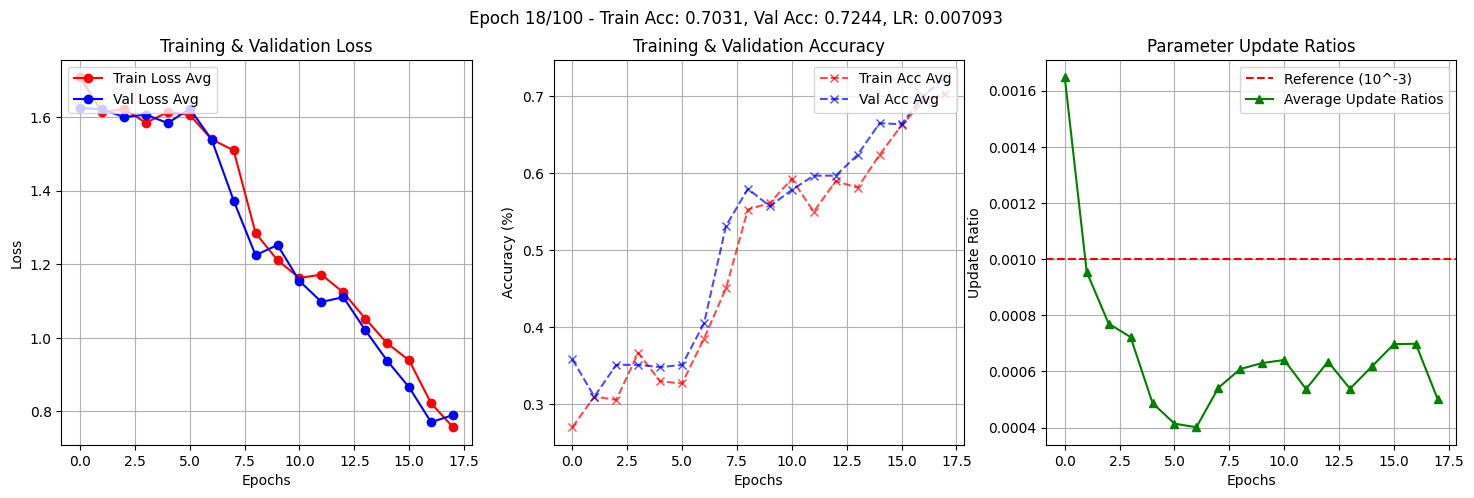

New best validation accuracy: 0.7983, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.78:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.7518
Accuracy             |          75.80%
Precision            |          0.6477
Recall               |          0.6337
F1 Score             |          0.6287

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      503       1        25       11       36       5     
1       2        35       0        5        14       10    
2       18       3       209       5        14       26    
3       3        15       0        72       68       1     
4       15       5        0        40      634       1     
5       31       20      104       4        2        63    
------------------------------------------------------------


# GRU ( Implementation From scratch )

In [ ]:
class GRU(nn.Module):
    def __init__(self, in_dim, h_dim, bias = False, device = 'cpu'):
        super(GRU, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.bias = bias
        self.device = device

        self.i2h = nn.Linear(in_dim, 3 * h_dim, bias=bias).to(device)    # [b, s, 3 x o]
        self.h2h = nn.Linear(h_dim, 3 * h_dim, bias=bias).to(device)   # [b, o, 3 x o]

        if in_dim != h_dim:
            self.res_proj = nn.Linear(in_dim, h_dim, bias=bias).to(device)
        else:
            self.res_proj = None

        self.init_parameters()
        self.to(device)

    def init_parameters(self):
        std = 1.0 / torch.sqrt(torch.tensor(self.in_dim, dtype=torch.float))
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, h = None):
        if h is None:
            h = Variable(x.new_zeros(x.size(0), self.h_dim))  # [b, o]

        gts = self.i2h(x) + self.h2h(h)                         # [b, s, 3*o]

        gts = self.i2h(x) + self.h2h(h)                         # [b, s, 3*o]
        rgt, zgt, hgt = gts.chunk(3, 1)                         # gts ==> [r, z, h]

        r = torch.sigmoid(rgt)                                  # [b, s, o]
        z = torch.sigmoid(zgt)                                  # [b, s, o]
        g = torch.tanh(r * hgt + (1 - r) * h)                   # [b, s, o]

        h = (1 - z) * h + z * g                                 # [b, s, o]

        h = h + self.res_proj(x) if self.res_proj is not None else h + x * 0.5

        return h

In [ ]:
class GRUBlock(nn.Module):
    def __init__(self, in_dim, h_dim, n_unit, bias=False, device="cpu"):
        super(GRUBlock, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device

        self.units = nn.ModuleList([GRU(in_dim=in_dim, h_dim=h_dim, bias=bias, device=device) for _ in range(n_unit)])

    def forward(self, x, xh = None):
        b, s, _ = x.shape   # [b, s, e]

        if xh is None:
            h0 = Variable(torch.zeros(self.n_unit, b, self.h_dim, device=self.device))            # [s, b, o]
        else:
            h0 = xh                                                                                 # [s, b, o]

        xhs = [(h0[u, :, :], h0[u, :, :]) for u in range(self.n_unit)]

        for i in range(s):
            chr = x[:, i, :]                            # [b, e]
            unit = self.units[i]                        # one LSTM unit

            xhs[i] = None if i == 0 else xhs[i - 1]
            h = unit(chr, xhs[i])                       # [b, h], [b, h]
            xhs[i] = h

        return h

In [ ]:
class GloveGRU(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, n_class, bias=True, d_rate=0.0, device="cpu"):
        super(GloveGRU, self).__init__()

        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.n_emb = n_emb

        self.emb = GloveEmbedder(n_emb=self.n_emb)

        self.rnn = GRUBlock(
            in_dim=self.n_emb,
            h_dim=self.h_dim,
            n_unit=self.n_unit,
            bias=bias,
            device=self.device,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = self.emb(x)    # (b, t, e)
        x = self.rnn(x)    # (b, t, h)
        x = self.dropout(x)  # (b, h or h*2)
        x = self.fc(x)       # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = GloveGRU(
    n_emb=100,
    h_dim=100,
    n_unit=20,
    n_class=6,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100 # fixed, just a reminder i may change it
h_dim = 100 # to use pure residual connection
n_unit = max_seq_len
n_class = len(class_cat)
d_rate = 0.3
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 2e-3
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.99

# Training configuration
n_epoch = 400
n_step = 20

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = GloveGRU(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    n_class=n_class,
    bias=True,
    d_rate=d_rate,
    device=device,
)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

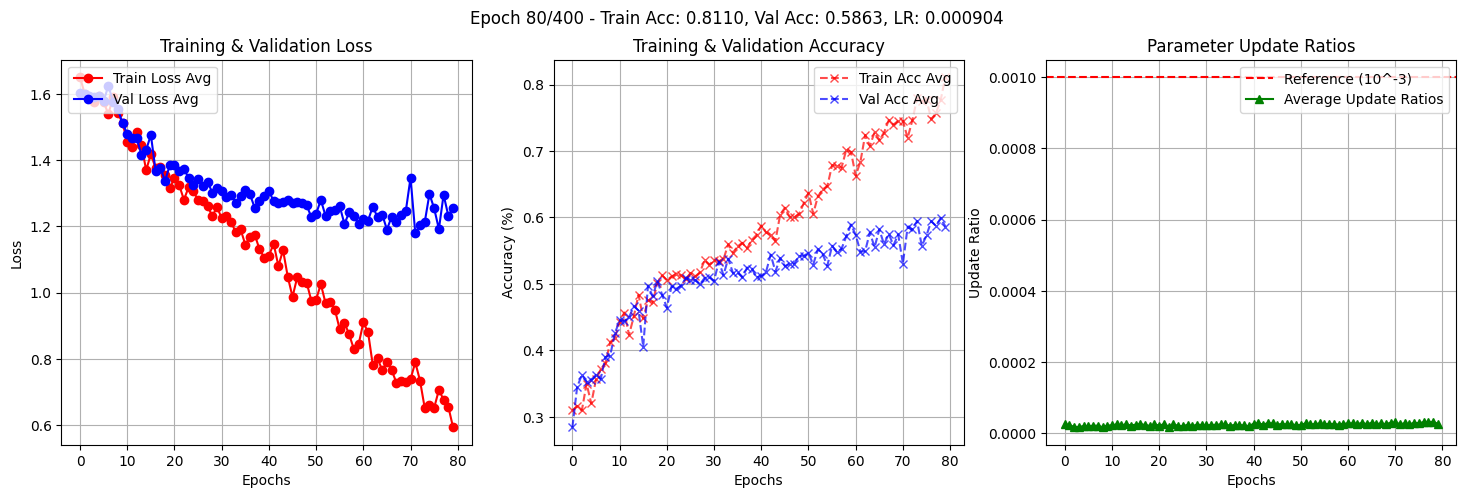

New best validation accuracy: 0.6094, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.60:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          1.3096
Accuracy             |          58.50%
Precision            |          0.4658
Recall               |          0.4472
F1 Score             |          0.4517

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      356       1        81       31       79       33    
1       6        6        6        2        36       10    
2       68       2       140       5        30       30    
3       18       0        12       52       76       1     
4       50       11       21       65      531       17    
5       55       11       44       1        28       85    
------------------------------------------------------------
